# Similarity-preserving representations: place-like fields

Reproduces Fig. 7 (Appendix H): the ratemaps and spatial similarity function for a
population whose generator eigenvalues are drawn from a Gaussian rather than placed on
a ring.

Eq. 4 is a discrete inverse Fourier transform of the eigenvalue spectrum, so *choosing
the eigenvalue distribution is choosing the similarity function* — no optimization is
involved. Appendix I samples eigenvalues from $\mathcal{N}(0, 2\sigma^2)$ to target
$C(\Delta) \approx e^{-\sigma^2\Delta^2}$, and Appendix H applies that to space. The
units come out heterogeneous and spatially localized: *place-like*, though the paper is
explicit that this is a proof of concept and does not capture the sparsity,
overdispersion or multi-field structure of real place cells.

**Mind the factor of two.** `gaussian_eigenvalues`' `scale` is the standard deviation of
the *eigenvalues*, while the paper's $\sigma$ is the width of the *similarity*:
$\text{scale}^2 = 2\sigma^2$, so $C(\Delta) \approx e^{-\text{scale}^2\Delta^2/2}$. The
default $\text{scale} = \sqrt{2}$ is Appendix H's $\mathcal{N}(0, 2)$ and gives
$C(\Delta) \approx e^{-\Delta^2}$. The last cell checks this.

**Parameters.** $N = 256$ and $\mathcal{N}(0, 2)$ are Appendix H; the $[-2, 2]$ domain is
Appendix A. The original notebook used $N = 300$ from `data/parameters/sigma_*_pc.pt`
over $[-1.5, 1.5]$.

Unlike the roots-of-unity spectrum, a Gaussian draw is **not** reconstructible without
its seed, and the seed behind those cached files was never recorded (see
`KNOWN_ISSUES.md`). Neither was the mixing matrix $R$ in the original notebook, so the
published panels were never exactly reproducible. This notebook draws an equivalent
seeded spectrum instead: the individual fields differ from the published ones, the
statistics and the similarity function do not.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch

import expmap
from expmap.analysis import batch_inference, compute_ratemaps, compute_similarity, rectify
from expmap.generators import block_diag_skew, build_generators, gaussian_eigenvalues
from expmap.linalg import random_orthogonal_matrix, starting_state
from expmap.model import ExponentialMap
from expmap.plotting import ratemap_collage
from expmap.simulation import generate_uniform_positions

# Figure parameters. N = 256 and scale = sqrt(2), i.e. N(0, 2), are Appendix H;
# the [-2, 2] domain is Appendix A. SEED fixes the spectrum, the mixing matrix R
# and the position sampling.
N = 256
SCALE = np.sqrt(2)
ARENA_SIZE = 2.0
BINS = 32
BATCH_SIZE, BATCHES = 50, 500
RECTIFY = False  # apply ReLU to the population vectors before binning
SEED = 0

REPO_ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
FIGURE_DIR = REPO_ROOT / "figures"
FIGURE_DIR.mkdir(exist_ok=True)

In [2]:
# gaussian_eigenvalues returns eigenvalues directly, unlike the roots-of-unity case
# where it is angles that come back. x and y are drawn independently, so the wavevectors
# scatter over the plane instead of sitting on a ring.
ev_x = gaussian_eigenvalues(N, scale=SCALE, seed=SEED)
ev_y = gaussian_eigenvalues(N, scale=SCALE, seed=SEED + 1)
sigma_x = block_diag_skew(ev_x)
sigma_y = block_diag_skew(ev_y)

R = random_orthogonal_matrix(N, seed=SEED)
p0 = starting_state(R)
Gx, Gy = build_generators(sigma_x, sigma_y, R)

model = ExponentialMap(Gx, Gy)

# Independent spectra still commute: both sigmas are block diagonal on the same 2x2
# blocks, and those blocks are all multiples of the same generator.
assert torch.allclose(Gx @ Gy, Gy @ Gx, atol=1e-5), "generators must commute"
assert torch.allclose(Gx, -Gx.T, atol=1e-6), "generators must be skew-symmetric"

# The above is exactly what the convenience constructor builds.
reference, p0_reference = expmap.place_cell_model(N=N, scale=SCALE, seed=SEED)
assert torch.equal(model.Gx, reference.Gx) and torch.equal(p0, p0_reference)

print(f"Number of units: {len(Gx)}")

Number of units: 256


In [3]:
r_batch = generate_uniform_positions(BATCHES, BATCH_SIZE, ARENA_SIZE, seed=SEED)

p_ = batch_inference(model, r_batch, p0)
r = np.concatenate(r_batch)

# Skew-symmetric generators transport p0 by orthogonal maps, so the norm is constant
# here just as in the roots-of-unity case: the spectrum sets the similarity function,
# not whether the representation is equinorm.
print(f"||p|| = {np.linalg.norm(p_, axis=1).mean():.6f} +/- {np.linalg.norm(p_, axis=1).std():.2e}")

  0%|          | 0/500 [00:00<?, ?it/s]

  1%|          | 3/500 [00:00<00:23, 21.08it/s]

  1%|          | 6/500 [00:00<00:24, 20.31it/s]

  2%|▏         | 9/500 [00:00<00:24, 20.07it/s]

  2%|▏         | 12/500 [00:00<00:24, 20.02it/s]

  3%|▎         | 15/500 [00:00<00:26, 18.59it/s]

... (190 outputs left out)

 99%|█████████▉| 495/500 [00:24<00:00, 20.10it/s]

100%|█████████▉| 498/500 [00:25<00:00, 20.25it/s]

100%|██████████| 500/500 [00:25<00:00, 19.81it/s]

||p|| = 1.000000 +/- 5.86e-07


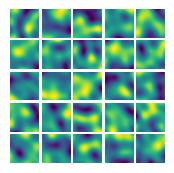

In [4]:
p = rectify(p_) if RECTIFY else p_

ratemaps = compute_ratemaps(r[:, 0], r[:, 1], p, bins=BINS)

fig, _ = ratemap_collage(ratemaps, rows=5, cols=5, figsize=(2, 2))
fig.savefig(FIGURE_DIR / "pc_ratemaps.svg", dpi=300, transparent=True, bbox_inches="tight")
fig.savefig(FIGURE_DIR / "pc_ratemaps.png", dpi=300, transparent=True, bbox_inches="tight")

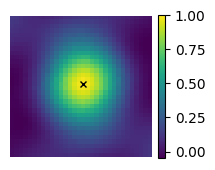

In [5]:
a = BINS // 2
similarity = compute_similarity(ratemaps, ref_bin=(a, a))

edges = np.linspace(-ARENA_SIZE, ARENA_SIZE, BINS + 1)
centres = (edges[:-1] + edges[1:]) / 2

plt.figure(figsize=(2, 2))
# .T because similarity is indexed (bins_x, bins_y) and imshow wants (row=y, col=x).
plt.imshow(
    similarity.T,
    vmax=1,
    extent=(-ARENA_SIZE, ARENA_SIZE, -ARENA_SIZE, ARENA_SIZE),
    origin="lower",
)
plt.plot(centres[a], centres[a], "kx", markersize=5)  # the reference bin centre
plt.colorbar(fraction=0.046, pad=0.04)
plt.axis("off")
plt.savefig(FIGURE_DIR / "pc_similarity.svg", dpi=300, transparent=True, bbox_inches="tight")
plt.savefig(FIGURE_DIR / "pc_similarity.png", dpi=300, transparent=True, bbox_inches="tight")

max |empirical - Eq. 4|       = 1.46e-06
rms |empirical - Gaussian|    = 0.0613
  finite-N noise floor 1/sqrt(N/2) = 0.0884


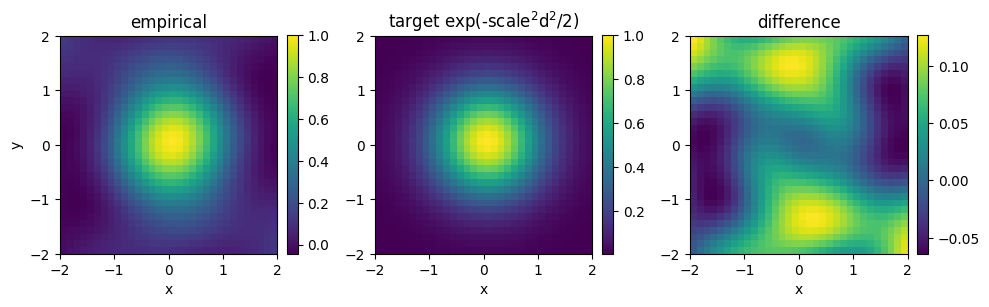

In [6]:
# Two checks, at different strengths.
#
# Eq. 4 is exact for any spectrum, so it should agree to float32 precision.
# The Gaussian target is only a Monte Carlo estimate of the Fourier integral over
# N // 2 samples (App. I), so it holds to roughly 1/sqrt(N // 2) -- the visible
# ripple away from the centre is that finite-N error, not a bug.
X, Y = np.meshgrid(centres, centres, indexing="ij")
grid_positions = torch.tensor(np.stack([X.ravel(), Y.ravel()], axis=1), dtype=torch.float32)
with torch.no_grad():
    p_grid = model(grid_positions, p0).numpy()

empirical = compute_similarity(p_grid.T.reshape(N, BINS, BINS), ref_bin=(a, a))

dx = centres[:, None] - centres[a]
dy = centres[None, :] - centres[a]
eq4 = sum((2 / N) * np.cos(ev_x[i] * dx + ev_y[i] * dy) for i in range(N // 2))
gaussian = np.exp(-(SCALE**2) * (dx**2 + dy**2) / 2)

print(f"max |empirical - Eq. 4|       = {np.nanmax(np.abs(empirical - eq4)):.2e}")
print(f"rms |empirical - Gaussian|    = {np.sqrt(np.mean((empirical - gaussian) ** 2)):.4f}")
print(f"  finite-N noise floor 1/sqrt(N/2) = {1 / np.sqrt(N // 2):.4f}")

fig, axs = plt.subplots(1, 3, figsize=(10, 3.2))
for ax, img, title in zip(
    axs,
    [empirical.T, gaussian.T, (empirical - gaussian).T],
    ["empirical", "target exp(-scale$^2$d$^2$/2)", "difference"],
):
    im = ax.imshow(img, extent=(-ARENA_SIZE, ARENA_SIZE, -ARENA_SIZE, ARENA_SIZE), origin="lower")
    ax.set_title(title)
    ax.set_xlabel("x")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
axs[0].set_ylabel("y")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "pc_similarity_vs_target.svg", dpi=300, transparent=True)